# Exam 1: The Heart Clinic

### Author: Elias Nicolas

## Introduction to Machine Learning

#### University of Redlands - DATA 301
#### Prof: Joanna Bieri [joanna_bieri@redlands.edu](mailto:joanna_bieri@redlands.edu)
#### [Class Website](https://joannabieri.com/machine_learning.html)

---

# Exam 1: The Heart Clinic

**Released Thursday 10/1 after class. Due Monday 10/5 at 11:59pm.** This covers Days 1 to 8.

In this exam you will build a model that helps a heart clinic decide which patients to send for a big, expensive test. You will do everything we have practiced so far: split the data, build a pipeline, use cross validation to choose a model, read the ROC curve and the confusion matrix, choose a threshold, and then use the test set one time at the very end.

There are two parts.

* **Part 1 is handwritten.** Three short essays about splitting your data, cross validation, and pipelines.
* **Parts 2 to 8 are code** in this notebook, with short written answers along the way.

---

## How this notebook works

There are two kinds of things for you to do. Look for these:

1. **Write the code under the comments.** The comments in each code cell tell you what to write on the lines right below them. When a comment starts a line like `heart = `, finish that line. **Use the variable names that are given to you**, because later cells need them. Some lines are already written for you, just leave those and run them.
2. **Write an answer in words.** Every question that needs a written answer has its own cell right below it that says **Your answer**. Double click that cell and type your answer there. Most answers are 2 to 4 sentences.

The exam starts with lots of help and gives you less as you go. By the end you are writing the code yourself, the same way you did in the homework.

Each part tells you **where to look** in the class notes. Copying code from the notes or from your own homework and changing the names is expected! That is how people actually work.

---

## The rules

**This exam is individual and AI-free.** This is the one place in the course where no AI is allowed (see the syllabus).

**You CAN use:**

* Your own notes, handwritten or typed.
* Your own code from the daily and weekly homework.
* Everything on the class website: the notes, the slides, the videos.
* The textbook.
* The documentation for scikit-learn, pandas, numpy and matplotlib.

**You CAN NOT use:**

* Any AI tool. That means ChatGPT, Claude, Gemini, Copilot, and anything like them. It also means the **AI autocomplete** built into editors like VS Code, Colab or JupyterLab plugins. Turn it off before you start.
* Help from another person. That includes classmates, friends, tutors and online forums.

**If you are stuck**, email me. I will answer questions about what a question is asking, and I will tell you if something in the exam is broken. I will not tell you how to do it.

**Honor statement.** Type your name in the cell right below the rules to say that the work in this exam is your own, and that you did not use AI or get help from another person.

---

## How to turn this in

There are two things to turn in:

1. **This notebook goes on Canvas, not GitHub.** Upload the `.ipynb` file to the `Exam 1 (Take-Home)` assignment by Monday 10/5 at 11:59pm. Before you upload it, restart the kernel and run every cell from the top, so I see the same numbers you do.
2. **Bring your handwritten Part 1 to class on Tuesday 10/6.** Make sure I can read it!

**How long will it take?** Plan on about **three hours** in total: about half an hour for the essays and the rest for the code. The code runs in a few seconds, except the random forest search, which can take a minute or two on an older laptop.

---


**Honor statement.** I did this exam by myself. I did not use AI, and I did not get help from another person.

Name: Elias Nicolas

# Part 1: Three short essays, by hand

**Write these on paper. Do not type them.** Just like the Q boxes in the notes, writing an explanation by hand is slow, and it is hard to write one you do not understand. That is why it is here.

Write **one paragraph** for each essay, about 5 to 8 sentences. Your paragraph should answer the questions listed under the essay. Essay 2 also needs a small drawing. Your notes are open, but write it in your own words.

---

**Essay 1: Why do we split the data into training and testing sets?**

In your paragraph, answer these questions:

1. What goes wrong if you score a model on the same data you trained it on? Use an example from class. (The Day 2 polynomial is a good one.)
2. Why do you only get to use the test set once, at the very end? What goes wrong if you check the test score after every change you make?

---

**Essay 2: What is cross validation and why do we use it?**

1. **Draw a picture** of 5-fold cross validation. Your drawing should show which rows are used for training and which rows are used for scoring in each of the five rounds.
2. Cross validation gives you five scores, and they are not all the same. How much they spread out tells you something. When you compare two models, how do you use the spread to decide whether one model is really better than the other?

---

**Essay 3: What is a pipeline and what problem does it solve?**

1. What does a `Pipeline` do when you call `.fit()`? What does it do when you call `.predict()`?
2. Give one example of **leakage** that a pipeline prevents. For example, filling in missing values or scaling using **all** of the rows before you split. Explain what goes wrong.

---

## The story - Read this, don't skip it!

You will need the story to answer questions all through the exam.

**This data is made up.** I built it from the patterns in a real dataset of heart patients from the Cleveland Clinic (A. Janosi, W. Steinbrunn, M. Pfisterer and R. Detrano, *Heart Disease*, 1989, UCI Machine Learning Repository, doi:10.24432/C52P4X, CC BY 4.0). The 2000 patients in this file do not exist, and nothing in it should be used to make a real medical decision. But the story is a real kind of problem, so think about it as you work.

The **Valley Heart Clinic** (also made up) is a busy walk-in clinic. People come in with chest pain, shortness of breath, or a doctor's note that says "get your heart checked". The clinic can do the simple things itself: blood pressure, a blood test, an ECG, an exercise test on a treadmill, and a heart scan.

What the clinic can not do is an **angiogram**. That is the test that gives the final answer: a doctor puts a thin tube into the arteries of the heart and looks for blockages. The angiogram is done at the hospital across town. It costs thousands of dollars, the wait is weeks long, and like any procedure it carries a small real risk.

So every day the clinic has to decide: **who gets sent for an angiogram, and who gets sent home?**

The clinic director pulled 2000 patient records from the clinic's computer system. For each one the hospital later reported whether the angiogram found heart disease. She wants to know if a model could help make the decision, and she told you three things when she handed over the file:

1. "About a third of our patients are women. A lot of the research on heart disease was done on men."
2. "When the hospital sends back a result that shows heart disease, our system books a follow up with a cardiologist automatically. That is in the file too."
3. "Some of the tests do not get done for every patient, so there are blanks."

### What is in the data

| column | what it means |
|---|---|
| `patient_id` | the clinic's record number |
| `age` | age in years |
| `sex` | male or female |
| `chest_pain` | the kind of chest pain the patient came in with: typical angina, atypical angina, non-anginal pain, or asymptomatic (no chest pain) |
| `resting_bp` | resting blood pressure (mm Hg) |
| `cholesterol` | cholesterol from the blood test (mg/dl) |
| `fasting_sugar_high` | 1 if fasting blood sugar is over 120 mg/dl, 0 if not |
| `rest_ecg` | resting ECG result: normal, ST-T abnormality, or enlarged ventricle |
| `max_heart_rate` | highest heart rate reached on the treadmill |
| `exercise_angina` | 1 if the treadmill brought on chest pain, 0 if not |
| `st_depression` | how far one part of the ECG dropped during exercise, compared to rest |
| `st_slope` | the shape of that part of the ECG at peak exercise: up, flat, or down |
| `vessels_colored` | how many of the major blood vessels (0 to 3) showed up on the scan |
| `thal` | result of the heart scan: normal, fixed defect, or reversible defect |
| `followup_booked` | 1 if a follow up with a cardiologist is booked, 0 if not |
| `heart_disease` | 1 if the angiogram found heart disease, 0 if not. **This is what we predict.** |

You do not need to know any medicine for this exam.

---

# Our goal

**GOAL: Build a classification model that predicts `heart_disease`.**

The clinic will use the model to decide who gets sent for an angiogram and who gets sent home. Here is the plan, one step for each part of the exam:

1. **Part 2:** Load the data. Figure out what we are predicting and which columns we are allowed to use. Think about what to do with NANs.
2. **Part 3:** Split off a test set and put it away. Then explore the training data.
3. **Part 4:** Build a pipeline that prepares the data and fits a logistic regression. Score it with cross validation.
4. **Part 5:** Try a random forest too, let grid search choose the settings for both models, and choose the better model.
5. **Part 6:** See how good the chosen model is, with the ROC curve and the confusion matrix.
6. **Part 7:** Choose the threshold, the probability where the model switches from "send home" to "send for an angiogram".
7. **Part 8:** Check the final model on the test set, one time, and write a note to the director.

If you get lost in the middle of the exam, come back here and find where you are in the plan.

---

# Part 2: Load the data and look at it

**Goal for this part:** load the data, look at what we are predicting, and decide which columns can NOT be used as features.

**2a.** Read in the data found at `data/heart_clinic.csv`. 

**There are missing values in this file**. You might need to open the `.csv` file (in VS Code or any text editor) to figure out how they are marked. Then use the `na_values` flag in `pd.read_csv` so pandas reads them as missing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Read in the csv data found at data/heart_clinic.csv and call it heart.
# Use na_values= to tell pandas how the missing values are marked in this file.
file ='data/heart_clinic.csv'
heart = pd.read_csv(file, na_values ='?')

# These lines are written for you. They print the size of the data and the missing values in each column.
print("rows and columns:", heart.shape)
print()
print("missing values per column:")
print(heart.isna().sum()[heart.isna().sum() > 0])

rows and columns: (2000, 16)

missing values per column:
cholesterol        170
vessels_colored     79
thal                60
dtype: int64


In [2]:
heart.dtypes

patient_id              int64
age                     int64
sex                    object
chest_pain             object
resting_bp              int64
cholesterol           float64
fasting_sugar_high      int64
rest_ecg               object
max_heart_rate          int64
exercise_angina         int64
st_depression         float64
st_slope               object
vessels_colored       float64
thal                   object
followup_booked         int64
heart_disease           int64
dtype: object

In [3]:
heart.head()

,patient_id,age,sex,chest_pain,resting_bp,cholesterol,fasting_sugar_high,rest_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,vessels_colored,thal,followup_booked,heart_disease
0,10001,79,female,non-anginal pain,137,209.0,0,ST-T abnormality,133,0,0.5,flat,0.0,normal,0,0
1,10002,52,female,asymptomatic,141,240.0,0,enlarged ventricle,134,1,1.9,flat,1.0,reversible defect,0,0
2,10003,47,female,non-anginal pain,146,307.0,0,normal,144,0,1.3,up,1.0,normal,0,0
3,10004,41,male,asymptomatic,93,154.0,0,enlarged ventricle,119,1,1.6,flat,0.0,reversible defect,1,1
4,10005,57,male,non-anginal pain,132,194.0,1,enlarged ventricle,160,0,0.0,up,0.0,normal,0,0


Look at the output above and answer:

1. How many patients are there?
2. How many variables are there?
3. Which columns have missing values, and how many are missing in each?

**Your answer:**

*1. There are 2000 patients in the dataset.*

*2. There are 16 values in the dataset.* 

*3. The column cholesterol has 170 missing values, vessels_colored has 79 values missing, and thal has 60 values missing (309 missing values total).*


**2b.** Now we make your labels, `y`, the thing we want to predict. We are predicting whether the patient has heart disease. Then look at how many patients have heart disease.

In [4]:
# Make y, the column we want to predict.
y = heart['heart_disease'] 

# Print how many patients have heart disease (1) and how many don't (0).
# HINT: .value_counts()
patients_with_heart_disease = y.value_counts()
print(patients_with_heart_disease)
print()

# Print the share of patients with heart disease, rounded to 3 places.
# HINT: y is all 0s and 1s, so the MEAN of y is the share of 1s.
share_with_heart_disease = round(y.mean(), 3)
print(f"The share of patients with heart disease: {share_with_heart_disease}")

heart_disease
0    1457
1     543
Name: count, dtype: int64

The share of patients with heart disease: 0.272


**2c.** Imagine a really lazy model that says "no heart disease" for EVERY patient.

1. What accuracy would it get? Use your numbers from above.
2. Would that model be any use to the clinic? Why or why not?

**Your answer:**

*1. This model would get an accuracy of 0.728 because if the share of patients with no heart disease is 0.728, than the model would predict that share correctly since it is simply saying "no heart disease" for every patient.*

*2. That model would be useless for the clinic as the goal of implementing our machine learning model is to accurately predict what patients should be sent to the hospital for an angiogram. Since the model is saying "no heart disease" for every patient, it directly fails at the previously defined goal for the clinic.*

**2d.** Not every column should be used to make predictions. `heart_disease` is the answer, so of course it can not be a feature. There are **two more** columns that should NOT be features.

1. Which two columns are they?
2. For each one, explain why it should not be used.

HINT: Go back to the story and reread what the director told you. For each column, ask yourself: would the clinic actually know this about a brand new patient on the day they walk in? And does it tell you anything about their heart?

**Your answer:**

*1. The two columns that should not be present in our model's features are "followup_booked" and "patient_id".*

*2. The variable "followup_booked" needs to be dropped becasue the presence of this column would cause a data leakage within our model, as the director mentioned in the story that "When the hospital sends back a result that shows heart disease, our system books a follow up with a cardiologist automatically. That is in the file too." To ensure our model does not overfit, "followup_booked" should not be a feature. The "patient_id" feature should be dropped as well since it is not relevant in providing our model with any data regarding their heart. It is just a filler column that would be useless for our model in terms of predicting heart diseases, also if they are a brand new patient they may not even be assigned a patient id on the day they walk in, making it beneficial for us to drop before moving forward.*

---

# Part 3: Split the data, then explore

**Goal for this part:** put a test set away where we can't see it, then look for patterns in the training data.

**Where to look:** the `train_test_split` code in the Day 5 notes.

We split the data BEFORE we explore it. If we look at all of the data, what we notice could change what we build, and then the test set is not really unseen anymore. So from here on we only explore the training rows.

**3a.** Make `X`, the features, and split the data into a training set and a test set. Write the code under the comments.

When you run it you should see **1500 training rows and 500 test rows**. If you don't, check your code.

In [5]:
from sklearn.model_selection import train_test_split

# Make X by dropping three columns from heart: heart_disease (the answer) and the two columns you decided can not be features.

##NUMERICAL DATA
number_columns = ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression",
                  "vessels_colored", "fasting_sugar_high", "exercise_angina"]

##CATEGORICAL DATA
text_columns = ["chest_pain", "rest_ecg", "st_slope", "thal", "sex"]

X = heart[number_columns + text_columns]

# Split X and y into X_train, X_test, y_train, y_test with train_test_split:
#   - the test set is 25 percent of the data (test_size wants a decimal)
#   - stratify on y, so the share of heart disease is the same in both pieces
#   - random_state=42, so everyone gets the same split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42)     

# These lines are written for you.
print("training rows:", len(X_train))
print("test rows:    ", len(X_test), "  (put away until the end)")
print("share with heart disease, train:", round(y_train.mean(), 3))
print("share with heart disease, test: ", round(y_test.mean(), 3))

training rows: 1500
test rows:     500   (put away until the end)
share with heart disease, train: 0.271
share with heart disease, test:  0.272


NOTE - This time we do NOT make a separate validation set. Every choice is made with cross validation on the training rows. Cross validation does the job that the validation set used to do. We don't touch `X_test` or `y_test` again until the end!

**3b.** Above you found a column that leaks the answer, `followup_booked`. Let's see how bad it is! Run the cell below. It is written for you. It shows the share of training patients with heart disease, split up by whether they had a follow up booked (0 = no, 1 = yes).

In [6]:
# followup_booked for the training patients only, lined up by row with y_train
followup_train = heart.loc[X_train.index, "followup_booked"]

y_train.groupby(followup_train).mean()

followup_booked
0    0.028653
1    0.832230
Name: heart_disease, dtype: float64

If we had left `followup_booked` in, the model would look amazing in cross validation. But...

1. What share of the patients WITH a follow up have heart disease? What share WITHOUT a follow up?
2. Now think about a brand new patient who walks into the clinic today. What would their `followup_booked` be? What would a model that needs this information do for them?

**Your answer:**

*1. The share of patients with a follow up that have heart diseases is about 0.83, while the share without a follow up is only about 0.03.*

*2. A brand new patient who walks into the clinic would have a "followup_booked" value of 0 (representing that they do not have a follow up booked). In this case, our model will falsely misrepresent them as they will presume that the new patient does not have heart disease when they may infact have it. This is crucial as the tradeoff in this case is putting a human life at risk, meaning we have no margin for error whatsoever when it comes to our model as it is costly when it is wrong.*

**3c.** The director told us that a lot of heart research was done on men. Let's see if the warning signs look the same for men and for women. Find the share with heart disease for each sex and each kind of chest pain, using the training rows only.

In [7]:
# Group y_train by BOTH the sex column and the chest_pain column of X_train, then take the mean.
# HINT: groupby can take a list of columns, like this: y_train.groupby([first_column, second_column]).mean()
sex_train = heart.loc[X_train.index, "sex"]
chest_pain_train = heart.loc[X_train.index, "chest_pain"]

y_train.groupby([sex_train, chest_pain_train]).mean()

sex     chest_pain      
female  asymptomatic        0.200000
        atypical angina     0.113402
        non-anginal pain    0.017544
        typical angina      0.294118
male    asymptomatic        0.606362
        atypical angina     0.037267
        non-anginal pain    0.123016
        typical angina      0.044944
Name: heart_disease, dtype: float64

Look at the table above and answer:

1. For **men**, which kind of chest pain has the highest share of heart disease?
2. For **women**, is it the same kind of chest pain?
3. Only about a third of the patients are women. Why might this be a problem for a model trained on this data?

**Your answer:**

*1. For men, the kind of chest pain with the highest share of heart disease is asymptomatic.*

*2. For women, the kind of chest pain with the highest share of heart disease is typical angina, which is not the same as men.*

*3. This would be a problem for a model trained on this data because it would underrepresent the amount of women who go to the director's clinic. If trained on this data, the model will recognize the patterns found within male patients and apply those to female patients. However, we can see that what is applicable to men is not always relevant to women.*

---

# Part 4: Build the pipeline

**Goal for this part:** build one pipeline that prepares the data and fits a logistic regression, then score it with cross validation.

**Where to look:** the `ColumnTransformer` and `Pipeline` code in the Day 8 notes.

Now we build one pipeline that does ALL of the preparation and the model in one go. This is the same set up as Day 8:

* The **number columns** get their missing values filled in with the median, and then they get scaled.
* The **text columns** get their missing values filled in with the most frequent value, and then they get turned into 0/1 dummy columns with `OneHotEncoder`.
* Then everything goes into a logistic regression.

The two column lists are written for you. NOTE - `fasting_sugar_high` and `exercise_angina` are already 0 and 1, so we put them with the numbers. They don't need dummy columns.

**4a.** Write the code under each comment. Each step starts the line with the variable name for you, so finish that line. The last line shows a picture of your pipeline so you can check it.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

number_columns = ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression",
                  "vessels_colored", "fasting_sugar_high", "exercise_angina"]
text_columns = ["chest_pain", "rest_ecg", "st_slope", "thal","sex"]

# Step 1: Make a pipeline called number_path for the number columns.
#         Use SimpleImputer and StandardScaler to fill in missing values with the median and scale the data.
number_path = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())])


# Step 2: Make a pipeline called text_path for the text columns.
#         Use SimpleImputer and OneHotEncoder to fill in missing values with the most frequent value
#         and turn the text into dummy columns.
text_path = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("dummy", OneHotEncoder(handle_unknown="ignore"))])



# Step 3: Make a ColumnTransformer called preprocessing that sends number_columns through number_path
#         and text_columns through text_path.
preprocessing = ColumnTransformer([
    ("num", number_path, number_columns),      
    ("cat", text_path, text_columns)])


# Step 4: Make a pipeline called full_pipeline that does preprocessing and then a LogisticRegression.
#         Name the two steps "prep" and "model". Later cells need these names.
full_pipeline = Pipeline([
    ("prep", preprocessing),
    ("model", LogisticRegression(max_iter=5000))])


full_pipeline     # shows a picture of your pipeline so you can check it

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'resting_bp',
                                                   'cholesterol',
                                                   'max_heart_rate',
                                                   'st_depression',
                                                   'vessels_colored',
                                                   'fasting_sugar_high',
                                                   'exercise_angina']),
                                                 ('cat',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('dummy',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['chest_pain', 'rest_ecg',
                                                   'st_slope', 'thal',
                                                   'sex'])])),
                ('model', LogisticRegression(max_iter=5000))])

**4b.** Now let's score the pipeline with 5-fold cross validation on the training data. The folds are made for you, so everyone gets the same folds.

We score with `scoring="roc_auc"`, the area under the ROC curve from Day 5. Closer to 1 is better. Write the code under each comment.

In [9]:
folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,          # mix the rows before cutting them into folds
    random_state=42)       # so everyone gets the same folds

# Step 1: Use cross_val_score to score full_pipeline on the training data, with our folds and scoring="roc_auc".
scores = cross_val_score(full_pipeline, X_train, y_train, cv=folds, scoring='roc_auc')

# Step 2: Print the five scores, their mean, and their standard deviation, rounded to 3 places.
print(f"The five scores: {scores}")
print(f"Mean average precision: {round(scores.mean(), 3)}")
print(f"Standard deviation: {round(scores.std(), 3)}")

The five scores: [0.93218332 0.91448221 0.92169795 0.91653614 0.92336093]
Mean average precision: 0.922
Standard deviation: 0.006


What is the mean ROC AUC, and what is the standard deviation (the spread)? Write them down, we will compare to these later.

**Your answer:**

*The mean ROC AUC is 0.922, the standard deviation (or spread) is 0.006.*

**4c.** The data has missing values in `cholesterol`, `vessels_colored`, and `thal`. This question is about how they get filled in. (This is your pipeline essay in action!)

1. Where in your code do those missing values get filled in? Name the step.
2. During each round of cross validation the pipeline trains on 4 folds and gets scored on the 5th fold. Say a patient in the 5th fold (the scoring fold) is missing their cholesterol. The median of which patients gets used to fill it in?
3. Why is that the right choice?

**Your answer:**

*1. I filled the missing values in step 4a. (cell 7), specifically in the lines ("fill", SimpleImputer(strategy="most_frequent")) and 
("fill", SimpleImputer(strategy="median")) outlined in our pipeline.*

*2. If a patient is missing their cholesterol than the median of the patients in the 1st, 2nd, 3rd, and 4th (which is the training fold in this case since the 5th fold is the testing fold) is used to fill it in.*

*3. That is the right choice because it prevents data leakage by using only values from the training fold to compute the median. This gives us an idea of how our model will perform under new and unseen data, which is the goal so that we can apply our model on new patient data after its finetuned.*

---

# Part 5: Choose the model and its settings

**Goal for this part:** let grid search find the best settings for a logistic regression and for a random forest, then choose ONE of them as our model.

**Where to look:** the `GridSearchCV` code in the Day 8 notes.

We are going to try two kinds of model and let grid search pick the best settings for each one. Then YOU choose which model to keep.

* **Logistic regression** has a setting called `C` that controls regularization, the same idea as Day 3. BEWARE! It is backwards from `alpha` in Ridge. A **small** `C` means **strong** regularization and a simpler model. A **big** `C` means weak regularization.
* **Random forest** from Day 6 has the settings `max_depth` (how deep each tree can grow) and `min_samples_leaf` (the fewest patients allowed in one leaf).

**5a.** Grid search for logistic regression. The grid is given to you. Write the code under each comment.

In [10]:
from sklearn.model_selection import GridSearchCV

logistic_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}    # there are TWO underscores between model and C

# Step 1: Make a GridSearchCV called logistic_search that searches full_pipeline over logistic_grid.
#         Use our folds, scoring="roc_auc", and return_train_score=True.
#         return_train_score=True makes it ALSO score each setting on the rows it trained on.
logistic_search = GridSearchCV(
    full_pipeline, # send in the pipeline
    logistic_grid, # send in the grid
    cv=folds,
    scoring="roc_auc",
    return_train_score=True)


# Step 2: Fit logistic_search on the training data.
logistic_search.fit(X_train, y_train)

# Step 3: Print the best settings and the best score, rounded to 3 places.
print("combinations tried:", len(logistic_search.cv_results_["params"]))
print("best settings:", logistic_search.best_params_)
print("best cross validated average precision:", round(logistic_search.best_score_, 3))

# Step 4: UNCOMMENT the line below and run it. It prints the spread (standard deviation) of the five fold scores
#         for the best setting. We have not used this before, so it is written for you.
print("spread across the folds:", round(logistic_search.cv_results_["std_test_score"][logistic_search.best_index_], 3))

combinations tried: 5
best settings: {'model__C': 0.1}
best cross validated average precision: 0.923
spread across the folds: 0.005


Now run the cell below, it is written for you. It shows every value of `C` the search tried, one per row.

NOTE: If you changed the variable names above (eg. log_search) then you might need to edit the code below.

* `mean_train_score` is the ROC AUC on the rows the model **trained** on.
* `mean_test_score` is the cross validated ROC AUC, on the fold it did **not** train on. (sklearn calls it "test", but this is the scoring fold. We still have not touched our test set!)
* `std_test_score` is the spread across the five folds.

In [11]:
logistic_results = pd.DataFrame(logistic_search.cv_results_)

logistic_results[["param_model__C", "mean_train_score", "mean_test_score", "std_test_score"]].round(3)

,param_model__C,mean_train_score,mean_test_score,std_test_score
0,0.01,0.924,0.920,0.007
1,0.10,0.930,0.923,0.005
2,1.00,0.931,0.922,0.006
3,10.00,0.931,0.921,0.007
4,100.00,0.931,0.921,0.007


**5b.** Grid search for the random forest. This works just like the logistic regression search above. The only change is the model at the end of the pipeline. It is now a random forest, so we need a **new** pipeline called `forest_pipeline`. The preprocessing stays the same.

**Use the names `forest_pipeline` and `forest_search`.** The cells below need them. Don't reuse the name `full_pipeline`, we still need that one.

This is the slowest cell in the exam. It can take a minute or two.

In [12]:
from sklearn.ensemble import RandomForestClassifier

forest_grid = {"model__max_depth": [3, 5, None],          # None means grow each tree until the leaves are pure
               "model__min_samples_leaf": [1, 5, 10]}     # the fewest patients allowed in one leaf

# Step 1: Make a pipeline called forest_pipeline that does preprocessing and then
#         RandomForestClassifier(n_estimators=200, random_state=42). Name the two steps "prep" and "model" again.
forest_pipeline = Pipeline([("prep", preprocessing),
                            ("model", RandomForestClassifier(n_estimators=200, random_state=42))])

# Step 2: Make a GridSearchCV called forest_search that searches forest_pipeline over forest_grid.
#         Use our folds, scoring="roc_auc", and return_train_score=True.
forest_search = GridSearchCV(
    forest_pipeline, # send in the pipeline
    forest_grid, # send in the grid
    cv=folds,
    scoring="roc_auc",
    return_train_score=True)

# Step 3: Fit forest_search on the training data.
forest_search.fit(X_train, y_train)

# Step 4: Print the best settings, the best score, and the spread across the folds, rounded to 3 places.
print("combinations tried:", len(forest_search.cv_results_["params"]))
print("best settings:", forest_search.best_params_)
print("best cross validated average precision:", round(forest_search.best_score_, 3))
print("spread across the folds:", round(forest_search.cv_results_["std_test_score"][forest_search.best_index_], 3))

combinations tried: 9
best settings: {'model__max_depth': None, 'model__min_samples_leaf': 5}
best cross validated average precision: 0.94
spread across the folds: 0.006


**5c.** Run the cell below, it is written for you. It shows every combination of settings the forest search tried, one per row. The columns are the same as in the logistic regression table.

NOTE: If you changed the variable names above (eg. forrest_search) then you might need to edit the code below.


In [13]:
results = pd.DataFrame(forest_search.cv_results_)

results[["param_model__max_depth", "param_model__min_samples_leaf",
         "mean_train_score", "mean_test_score", "std_test_score"]].round(3)

,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score
0,3,1,0.942,0.932,0.007
1,3,5,0.942,0.932,0.007
2,3,10,0.941,0.932,0.008
3,5,1,0.966,0.939,0.005
4,5,5,0.961,0.938,0.006
5,5,10,0.957,0.938,0.006
6,None,1,1.000,0.935,0.010
7,None,5,0.980,0.940,0.006
8,None,10,0.966,0.939,0.007


**5d.** Find the row where `max_depth` is None and `min_samples_leaf` is 1. This is a forest where every tree grows all the way down.

1. What is its training score (`mean_train_score`)? What does that number tell you the trees did with the training patients?
2. Its cross validated score (`mean_test_score`) is lower. Why? (Think about what happens when you score a model on the same data it trained on.)
3. Now look back at the logistic regression table. Is the gap between the training score and the cross validated score bigger or smaller than it is for this forest? Why?
4. Which settings did the search choose? What does that `min_samples_leaf` do to each tree? (Think about Day 6.)

**Your answer:**

*1. The training score is 1.000, this means that the tree correcly identified all the patients that had heart disease. However it is also a warning sign that overfitting was present when we use 1 as our min_samples_leaf value and no param_model__max_depth.*

*2. The cross validated score is lower because of the overfitting that occured when the model was trained since it was scored on the same values which it was trained on.*

*3. The gap between the training score and the cross validated score for the logistic regression model is smaller than the one for the forest because the forest model overfit as a result of the min_samples_leaf value being 1 and param_model__max_depth being none.*

*4. The model chose {'model__max_depth': None, 'model__min_samples_leaf': 5} for the settings of the forest, min_samples_leaf determines the amount of training samples used for each leaf. In this case, the best forest model had a min_samples_leaf of 5.*

**5e.** Now choose ONE model to use for the rest of the exam.

1. Write down the best ROC AUC and the spread for logistic regression and for the random forest.
2. How big is the difference between the two ROC AUCs? Is that difference bigger or smaller than the spread?
3. Which model do you choose, and why? Use the difference and the spread to explain.

**Your answer:**

*1. The best ROC AUC for the logistic regression model is 0.923 and the best ROC AUC for the random forest is 0.940.*

*2. The difference between the two rocs is 0.017, this is bigger than the difference between the respective spreads which is 0.001.*

*3. I choose to use the random forest model because it had the higher ROC AUC score compared to the logistic regression model. I am using the ROC AUC as the metric to judge which model to use moving forward because the difference in the spread across both models is visibly less than the difference of the averages, thus meaning that the difference between them is not due to chance but determined by who has the higher ROC AUC score. This is the random forest model in this scenario.*

Now save the model you chose as `chosen`. From here on, `chosen` is the model we use.

In [14]:
# Make chosen, the best pipeline from the search you chose. HINT: .best_estimator_
# It is already refit on all of the training rows, so it is ready to use.
chosen = forest_search.best_estimator_

chosen     # shows a picture of the pipeline you chose

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'resting_bp',
                                                   'cholesterol',
                                                   'max_heart_rate',
                                                   'st_depression',
                                                   'vessels_colored',
                                                   'fasting_sugar_high',
                                                   'exercise_angina']),
                                                 ('cat',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('dummy',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['chest_pain', 'rest_ecg',
                                                   'st_slope', 'thal',
                                                   'sex'])])),
                ('model',
                 RandomForestClassifier(min_samples_leaf=5, n_estimators=200,
                                        random_state=42))])

---

# Part 6: The ROC curve and the confusion matrix

**Goal for this part:** see how well our chosen model tells apart patients with and without heart disease, still using only the training data.

**Where to look:** the `cross_val_predict` code and the ROC curve plot in the Day 5 notes.

We still don't touch the test set! But to draw an ROC curve we need a probability for every patient. We get honest probabilities for the training patients with `cross_val_predict`. It gives each patient a probability from a model that did NOT train on that patient.

**6a.** Run this cell, it is written for you. You should see 1500 probabilities.

In [15]:
from sklearn.model_selection import cross_val_predict

y_prob_cv = cross_val_predict(
    chosen, X_train, y_train,
    cv=folds,
    method="predict_proba")[:, 1]     # method="predict_proba" gives probabilities instead of 0/1. [:, 1] keeps P(heart disease)

print("first five probabilities:", np.round(y_prob_cv[:5], 3))
print("number of probabilities:", len(y_prob_cv))

first five probabilities: [0.092 0.051 0.156 0.05  0.419]
number of probabilities: 1500


**6b.** Why can't we just use `chosen.predict_proba(X_train)` instead? HINT: `chosen` was trained on all of `X_train`. Look back at the training scores in the random forest table.

**Your answer:**



**6c.** Draw the ROC curve and find the ROC AUC. Write the code under each comment.

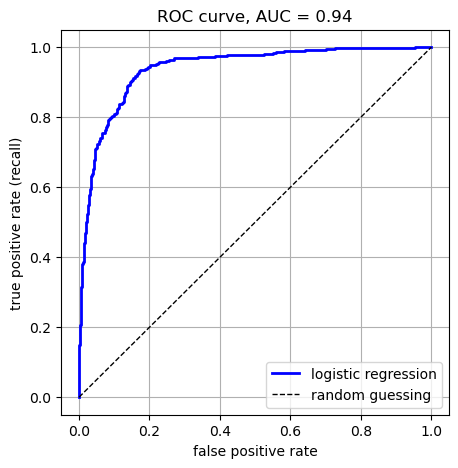

ROC AUC: 0.94


In [16]:
from sklearn.metrics import roc_curve, roc_auc_score

# Step 1: Use roc_curve with y_train and y_prob_cv to get fpr, tpr, and cutoffs.
fpr, tpr, cutoffs = roc_curve(y_train, y_prob_cv)  

# Step 2: Use roc_auc_score to get the area under the curve.
auc = roc_auc_score(y_train, y_prob_cv)  

# Step 3: Plot the ROC curve, fpr on the x axis and tpr on the y axis, with a dashed line for random guessing.
#         Label both axes and put the AUC in the title.
# Make a plot of the fpr = false positive rate versus tpr = true positive rate
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, "b-", linewidth=2, label="logistic regression")
# Here we just add a dashed line to show what random guessing would give
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="random guessing")

# Make it look nice
plt.xlabel("false positive rate")
plt.ylabel("true positive rate (recall)")
plt.title("ROC curve, AUC = " + str(round(auc, 3)))
plt.grid()
plt.legend()
plt.show()

print("ROC AUC:", round(auc, 3))

**6d.** Explain your AUC in plain words, the way we did for the wine in Day 5. Finish this sentence:

"If you pick one patient with heart disease and one without, at random, ..." 

**Your answer:**

If you pick one patient with heart disease and one without, at random the model gives the patient with heart disease the higher probability of heart disease 94% of the time.

**6e.** Now use the default threshold, 0.5, to turn the probabilities into predictions. Write the code under each comment.

In [17]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Step 1: Turn y_prob_cv into 0/1 predictions using a threshold of 0.5. Call them y_pred_cv.
threshold = 0.5
y_pred_cv = (y_prob_cv >= threshold).astype(int)  

# Step 2: Print the confusion matrix. The four numbers should add up to 1500.
print(confusion_matrix(y_train, y_pred_cv))
print("precision:", round(precision_score(y_train, y_pred_cv), 3))
print("recall:   ", round(recall_score(y_train, y_pred_cv), 3))

[[1023   70]
 [ 105  302]]
precision: 0.812
recall:    0.742


**6f.** Remember that in the confusion matrix the **rows** are what really happened and the **columns** are what the model said:

| | model says no (sent home) | model says yes (sent for an angiogram) |
|---|---|---|
| **really no heart disease** | top left | top right |
| **really has heart disease** | bottom left | bottom right |

For each of the four numbers in your confusion matrix, write one sentence that says what it means for the **patients**. Put the number in your sentence. For example: "___ patients have heart disease and were sent home." 

**Your answer:**

*1023 patients that did not have heart disease were sent home.*

*70 patients that did not have heart disease were sent for an angiogram.*

*105 patients that did have heart diseases were sent home.*

*302 patients that did have heart diseases were sent for an angiogram.*

---

# Part 7: Choose the threshold

**Goal for this part:** choose the probability where the model switches from "send home" to "send for an angiogram", and check how the model does for women and for men.

**Where to look:** the threshold loop in the Day 5 notes.

Here is how the clinic would use the model:

* The model gives each patient a probability of heart disease.
* If the probability is at or above the **threshold**, the model says YES and the patient is sent for an angiogram.
* If it is below the threshold, the model says NO and the patient is sent home.

So far we used 0.5, but nothing says 0.5 is right for this problem. In this part YOU choose the threshold.

**7a.** There are two kinds of mistakes the model can make:

* a **false alarm**: a patient without heart disease is sent for an angiogram.
* a **miss**: a patient with heart disease is sent home.

Answer:

1. Which mistake is worse for a patient? Use the story to explain.
2. To make that mistake happen less often, should you move the threshold UP from 0.5 or DOWN from 0.5? Why?
3. Relate these answers back to Precision and Recall.

**Your answer:**



**7b.** Let's see what happens at lots of different thresholds. For each threshold in the list, we want to know how many patients get sent for an angiogram, how many patients with heart disease get missed (sent home), the precision, and the recall. Write the code under each comment. Everything inside the loop is indented.

In [18]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for t in thresholds:
    # Step 1: Turn y_prob_cv into 0/1 predictions using the threshold t (compare each probability to t).
    y_pred_t = (y_prob_cv >= t).astype(int)

    # Step 2: Find the precision and the recall.
    p = precision_score(y_train, y_pred_t)
    r = recall_score(y_train, y_pred_t)

    # Step 3: Count the patients sent for an angiogram.
    n_sent = y_pred_t.sum()

    # Step 4: Count the patients with heart disease who were sent home. HINT: look at the confusion matrix.
    missed = confusion_matrix(y_train, y_pred_t)[1][0]

    # Step 5: Print t, n_sent, missed, p and r on one line, with labels. Round p and r to 3 places.
    print("threshold", t, "  number sent:", n_sent, " number missed:", missed, "  precision:", round(p, 3), "  recall:", round(r, 3))

threshold 0.1   number sent: 789  number missed: 11   precision: 0.502   recall: 0.973
threshold 0.2   number sent: 615  number missed: 21   precision: 0.628   recall: 0.948
threshold 0.3   number sent: 522  number missed: 43   precision: 0.697   recall: 0.894
threshold 0.4   number sent: 452  number missed: 73   precision: 0.739   recall: 0.821
threshold 0.5   number sent: 372  number missed: 105   precision: 0.812   recall: 0.742
threshold 0.6   number sent: 298  number missed: 149   precision: 0.866   recall: 0.634
threshold 0.7   number sent: 205  number missed: 222   precision: 0.902   recall: 0.455


**7c.** Choose your threshold! Look at the output from your loop and pick one threshold.

1. Which threshold did you choose?
2. What rule did you use to choose it? For example: "we can not miss more than 1 in 10 patients with heart disease."
3. What does it cost? Compare it to 0.5. How many MORE patients get sent for an angiogram? How many FEWER patients with heart disease get sent home?

**Your answer:**

*1. I chose the threshold 0.2, since we care more about having a high recall given the fact that a false negative could cost someone their life if misdiagnosed and 0.2 meets that requirement while having the best balance of precision and recall.*

*2. We can not miss more than more than 1 out of every 10 patients with heart disease.*

*3. This costs more patients who do not have heart disease to go in for an unecessary follow up appoitment. Compared to a threshold of 0.5, 243 more patients were sent for an angiogram but 84 fewer patients with heart disease got sent home.*

Now save your threshold. You will use it on the test set at the end.

In [19]:
# Save the threshold you chose as my_threshold
my_threshold = 0.2

**7d.** The director said a lot of the research on heart disease was done on men. Let's check our model! We will find the recall at **your** threshold for just the women, and then for just the men. Write the code under the comments.

In [20]:
# Step 1: Turn the cross validated probabilities, y_prob_cv, into 0/1 predictions using YOUR threshold, my_threshold.
#         Call the predictions y_pred_mine.
y_pred_mine = (y_prob_cv >= my_threshold).astype(int)  

# Step 2: This line is written for you. It makes an array of True and False, one for each training patient.
#         It is True if the patient is a woman and False if the patient is a man.
women = (X_train["sex"] == "female").values

# Step 3: Find the recall for just the women.
#         When you put a True/False array inside [ ], you keep only the rows that are True. So:
#             y_train[women]        the real answers (heart disease or not) for just the women
#             y_pred_mine[women]    the model's predictions for just the women
#         Send both of these to recall_score
recall_women = recall_score(y_train[women], y_pred_mine[women])

# Step 4: Now find the recall for just the men.
#         ~women flips every True to False and every False to True, so y_train[~women] keeps just the men.
recall_men = recall_score(y_train[~women], y_pred_mine[~women])

# Step 5: Print both recalls, rounded to 3 places, with labels.
print(f"Recall score for just women: {round(recall_women, 3)}")
print(f"Recall score for just men: {round(recall_men, 3)}")

Recall score for just women: 0.885
Recall score for just men: 0.96


**7e.** What did you find?

1. Write down the recall for the women and for the men.
2. In plain words, what does the difference mean for a woman who walks into the clinic with heart disease? (HINT: a recall of 0.8 means the model catches 8 out of 10 patients with heart disease and sends the other 2 home.)
3. Look back at the chest pain table for men and women. Why might the model do worse for women?

**Your answer:**

*1. The recall for the women is 0.885 and the recall for men is 0.96.*

*2. In plain words, this means that women have less of a chance than men to be correctly identified for heart disease.*

*3. The model will do worse for women because the data it is trained on is inherently biased, as outlined in the story the reasearch used came from clinical trials dominated by men. This leads to the underepresentation of women in our model, which is something to highlight as one third of the clinic patients are female.*

---

# Part 8: Use the test set, one time

**Goal for this part:** check our final model on patients it has never seen, and tell the director what we found.

**Where to look:** your own code above. You have already written every piece of this!

Every choice is made: the columns, the preparation, the model, its settings, and the threshold. `chosen` is already trained on all of the training data. Now we open the test set, ONE TIME.

NOTE - Run this cell once. If you change your threshold after you see the test results, you are using the test set to make a choice. That is exactly the mistake we split the data to avoid!

**8a.** In the cell below, write code that does these things, in this order:

1. Use `chosen` to get the probability of heart disease for each patient in `X_test`. Call them `y_prob_test`.
2. Turn them into 0/1 predictions using `my_threshold`. Call them `y_pred_test`.
3. Print the confusion matrix for the test set.
4. Print the precision, the recall, and the ROC AUC for the test set.
5. Print the recall for the women and for the men in the test set. HINT: make `women_test` the same way you made `women` above, but use `X_test`.
6. Print how many women with heart disease are in the test set.

In [21]:
# your code here
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, average_precision_score

y_prob_test = chosen.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= my_threshold).astype(int)

women_test = (X_test["sex"] == "female").values
recall_women_test = recall_score(y_test[women_test], y_pred_test[women_test])
recall_men_test = recall_score(y_test[~women_test], y_pred_test[~women_test])

print(confusion_matrix(y_test, y_pred_test))
print("test accuracy:         ", round(accuracy_score(y_test, y_pred_test), 3))
print("test precision:        ", round(precision_score(y_test, y_pred_test), 3))
print("test recall:           ", round(recall_score(y_test, y_pred_test), 3))
print("test average precision:", round(average_precision_score(y_test, y_prob_test), 3))
print("test ROC AUC:", round(roc_auc_score(y_test, y_prob_test), 3))
print()
print("test recall for women:           ", round(recall_women_test, 3))
print("women with heart disease in the test set:           ", y_test[women_test].sum())
print("test recall for men:           ", round(recall_men_test, 3))

[[294  70]
 [ 10 126]]
test accuracy:          0.84
test precision:         0.643
test recall:            0.926
test average precision: 0.861
test ROC AUC: 0.939

test recall for women:            0.789
women with heart disease in the test set:            19
test recall for men:            0.949


**8b.** Compare the test set to what you found with cross validation.

1. Are your test numbers close to your cross validated numbers? Give two examples.
2. How many women with heart disease are in the test set? If the model caught ONE more of them, how much would their recall go up? (HINT: 1 divided by the number of women with heart disease.)
3. Do you trust the test recall for women on its own? Why or why not?

**Your answer:**

*1. Yes the test numbers are close to the cross validated numbers, with most of them being slightly lower than the original cross validated numbers. For example, the recall for men originally was 0.96 on the training set while it was 0.949 on the testing set. Another instance includes, the total recall of both the training and testing set at a threshold of 0.2, with the testing set having a value of 0.926 while the training set had a recall of 0.948.*

*2. There are 19 women with heart disease in the test set, if the model caught one more of them the recall would go up.*

*3. No, I do not trust the test recall for women on its own because the data in which the model was trained on was biased as it underepresented women in comparison to men.*

**8c.** Write a short note (typed here) to the director of the Valley Heart Clinic, 3 or 4 sentences. She is not a data scientist, so no jargon! Don't use words like "AUC", "recall", or "precision". Your note should tell her:

1. What the model does.
2. How many patients it would send for an angiogram.
3. How many patients with heart disease it would miss.
4. What she should know about how it does for women.

**Your answer:**

The model takes the patient data that your clinic is already collecting and turns that into validated predictions on whether or not someone may have a heart disease thus, streamlining the angiogram process by weeding out patients who are less likely to be diagnosed. The model would send 196 patients in for an angiogram, and miss 10 patients out of a group of 500. It is also important to be more cautious if the patient is a woman when using this model because it is bias which leds it to underperform in comparison to male patients. For example, the model misses 2 out of 10 women with heart disease, while it misses only 1 out of 10 men with heart disease. 

---